In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
data=pd.read_csv("2 loan_approval_data.csv")
print(data.head())


   Applicant_ID  Applicant_Income  Coapplicant_Income Employment_Status   Age  \
0           1.0           17795.0              1387.0          Salaried  51.0   
1           2.0            2860.0              2679.0          Salaried  46.0   
2           3.0            7390.0              2106.0          Salaried  25.0   
3           4.0           13964.0              8173.0          Salaried  40.0   
4           5.0           13284.0              4223.0     Self-employed  31.0   

  Marital_Status  Dependents  Credit_Score  Existing_Loans  DTI_Ratio  \
0        Married         0.0         637.0             4.0       0.53   
1        Married         3.0         621.0             2.0       0.30   
2         Single         2.0         674.0             4.0       0.20   
3        Married         2.0         579.0             3.0       0.31   
4         Single         2.0         721.0             1.0       0.29   

   Savings  Collateral_Value  Loan_Amount  Loan_Term Loan_Purpose  \
0  19

In [ ]:
print(data.describe())


       Applicant_ID  Applicant_Income  Coapplicant_Income         Age  \
count    950.000000        950.000000          950.000000  950.000000   
mean     501.220000      10852.571579         5082.455789   39.971579   
std      289.608451       5061.632859         2943.161570   11.139797   
min        1.000000       2009.000000            1.000000   21.000000   
25%      250.250000       6730.750000         2472.750000   30.250000   
50%      499.500000      10548.000000         5205.500000   40.000000   
75%      752.750000      15190.000000         7620.750000   49.000000   
max     1000.000000      19988.000000         9996.000000   59.000000   

       Dependents  Credit_Score  Existing_Loans   DTI_Ratio       Savings  \
count  950.000000    950.000000      950.000000  950.000000    950.000000   
mean     1.474737    676.033684        1.950526    0.347263   9940.452632   
std      1.105067     71.346015        1.406246    0.144341   5860.736885   
min      0.000000    550.000000   

In [ ]:
print(data.isnull())


     Applicant_ID  Applicant_Income  Coapplicant_Income  Employment_Status  \
0           False             False               False              False   
1           False             False               False              False   
2           False             False               False              False   
3           False             False               False              False   
4           False             False               False              False   
..            ...               ...                 ...                ...   
995         False              True               False              False   
996         False             False               False              False   
997         False             False               False              False   
998         False             False               False              False   
999         False             False               False              False   

       Age  Marital_Status  Dependents  Credit_Score  Existing_

In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [ ]:
print(data.shape)

(1000, 20)


In [ ]:
catagorial_Column=data.select_dtypes(include=["object"]).columns
numerical_col=data.select_dtypes(include=["float64"]).columns

In [ ]:
from sklearn.impute import SimpleImputer
sim_impu=SimpleImputer(strategy="mean")
data[numerical_col]=sim_impu.fit_transform(data[numerical_col])

In [ ]:
data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [ ]:
sim_impu=SimpleImputer(strategy="most_frequent")
data[catagorial_Column]=sim_impu.fit_transform(data[catagorial_Column])

In [ ]:
data.isnull().sum()

,0
Applicant_ID,0
Applicant_Income,0
Coapplicant_Income,0
Employment_Status,0
Age,0
Marital_Status,0
Dependents,0
Credit_Score,0
Existing_Loans,0
DTI_Ratio,0


**EDA**

Text(0.5, 1.0, 'Loan')

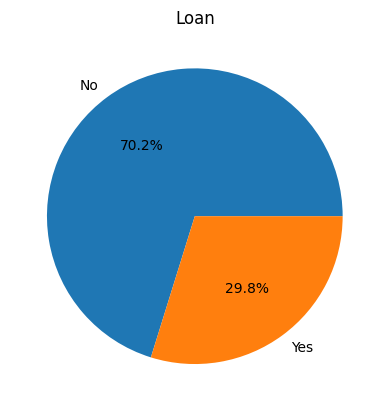

In [ ]:
class_count = data["Loan_Approved"].value_counts()
plt.pie(class_count, labels=["No", "Yes"], autopct="%1.1f%%")
plt.title("Loan")

<Axes: xlabel='Gender', ylabel='count'>

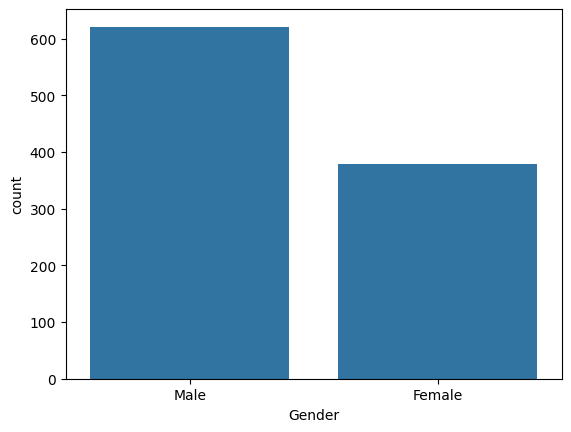

In [ ]:
gen_count=data["Gender"].value_counts()
sns.barplot(gen_count)

loan Applicant


<Axes: xlabel='Applicant_Income', ylabel='Count'>

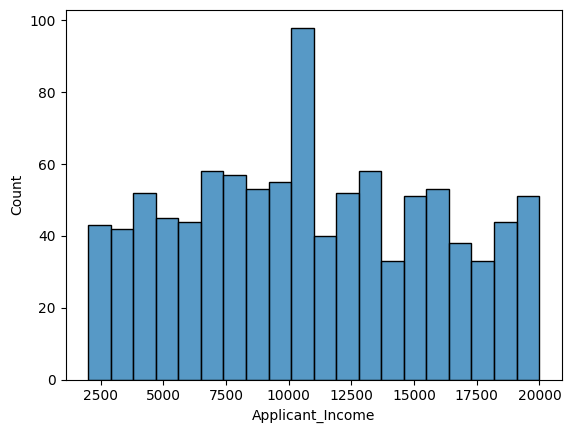

In [ ]:
sns.histplot(
    data=data,
    x="Applicant_Income",

    bins=20
)

**Credit score with income rate**

<Axes: xlabel='Credit_Score', ylabel='Count'>

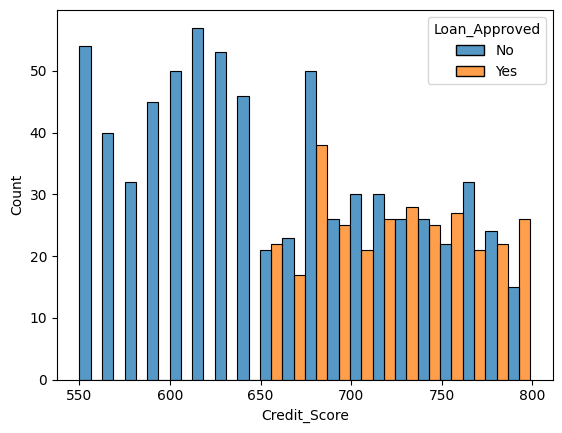

In [ ]:
sns.histplot (
    data=data,
    x="Credit_Score",
     hue="Loan_Approved",
    multiple="dodge",
    bins=20)

In [ ]:
data=data.drop(["Applicant_ID"],axis=1)

**Encoding**

In [ ]:
from sklearn.preprocessing import OneHotEncoder,LabelEncoder
le=LabelEncoder()
data["Education_Level"]=le.fit_transform(data["Education_Level"])
data["Loan_Approved"]=le.fit_transform(data["Loan_Approved"])

In [ ]:
data.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [ ]:
cols=["Employment_Status","Marital_Status","Loan_Purpose","Property_Area","Loan_Approved"]

In [ ]:
one = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = one.fit_transform(data[cols])
encoded_data = pd.DataFrame(encoded, columns=one.get_feature_names_out(cols), index=data.index)
data=pd.concat([data.drop(columns=cols),encoded_data],axis=1)


In [ ]:
data.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Employment_Status_Self-employed,Employment_Status_Unemployed,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Loan_Approved_1
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0


In [ ]:
num_col=data.select_dtypes(include="number")
corr_mat=num_col.corr()
print(corr_mat)

                                 Applicant_Income  Coapplicant_Income  \
Applicant_Income                         1.000000            0.007545   
Coapplicant_Income                       0.007545            1.000000   
Age                                     -0.023988            0.014306   
Dependents                              -0.026658           -0.026733   
Credit_Score                            -0.009818            0.058423   
Existing_Loans                          -0.010457            0.012418   
DTI_Ratio                               -0.009107            0.058078   
Savings                                 -0.028358           -0.015047   
Collateral_Value                         0.018789            0.009457   
Loan_Amount                             -0.024143            0.001596   
Loan_Term                               -0.033258            0.005894   
Education_Level                         -0.014593           -0.022918   
Employment_Status_Salaried              -0.000863  

In [ ]:
num_col.corr()["Loan_Approved_1"].sort_values(ascending=False)

,Loan_Approved_1
Loan_Approved_1,1.000000
Credit_Score,0.451175
Applicant_Income,0.119796
Loan_Purpose_Personal,0.034043
Marital_Status_Single,0.030182
Property_Area_Urban,0.025963
Collateral_Value,0.021868
Coapplicant_Income,0.004230
Loan_Purpose_Home,0.002118
Employment_Status_Self-employed,-0.001337


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Gender               

**Co-Relation Heat_Map**

<Axes: >

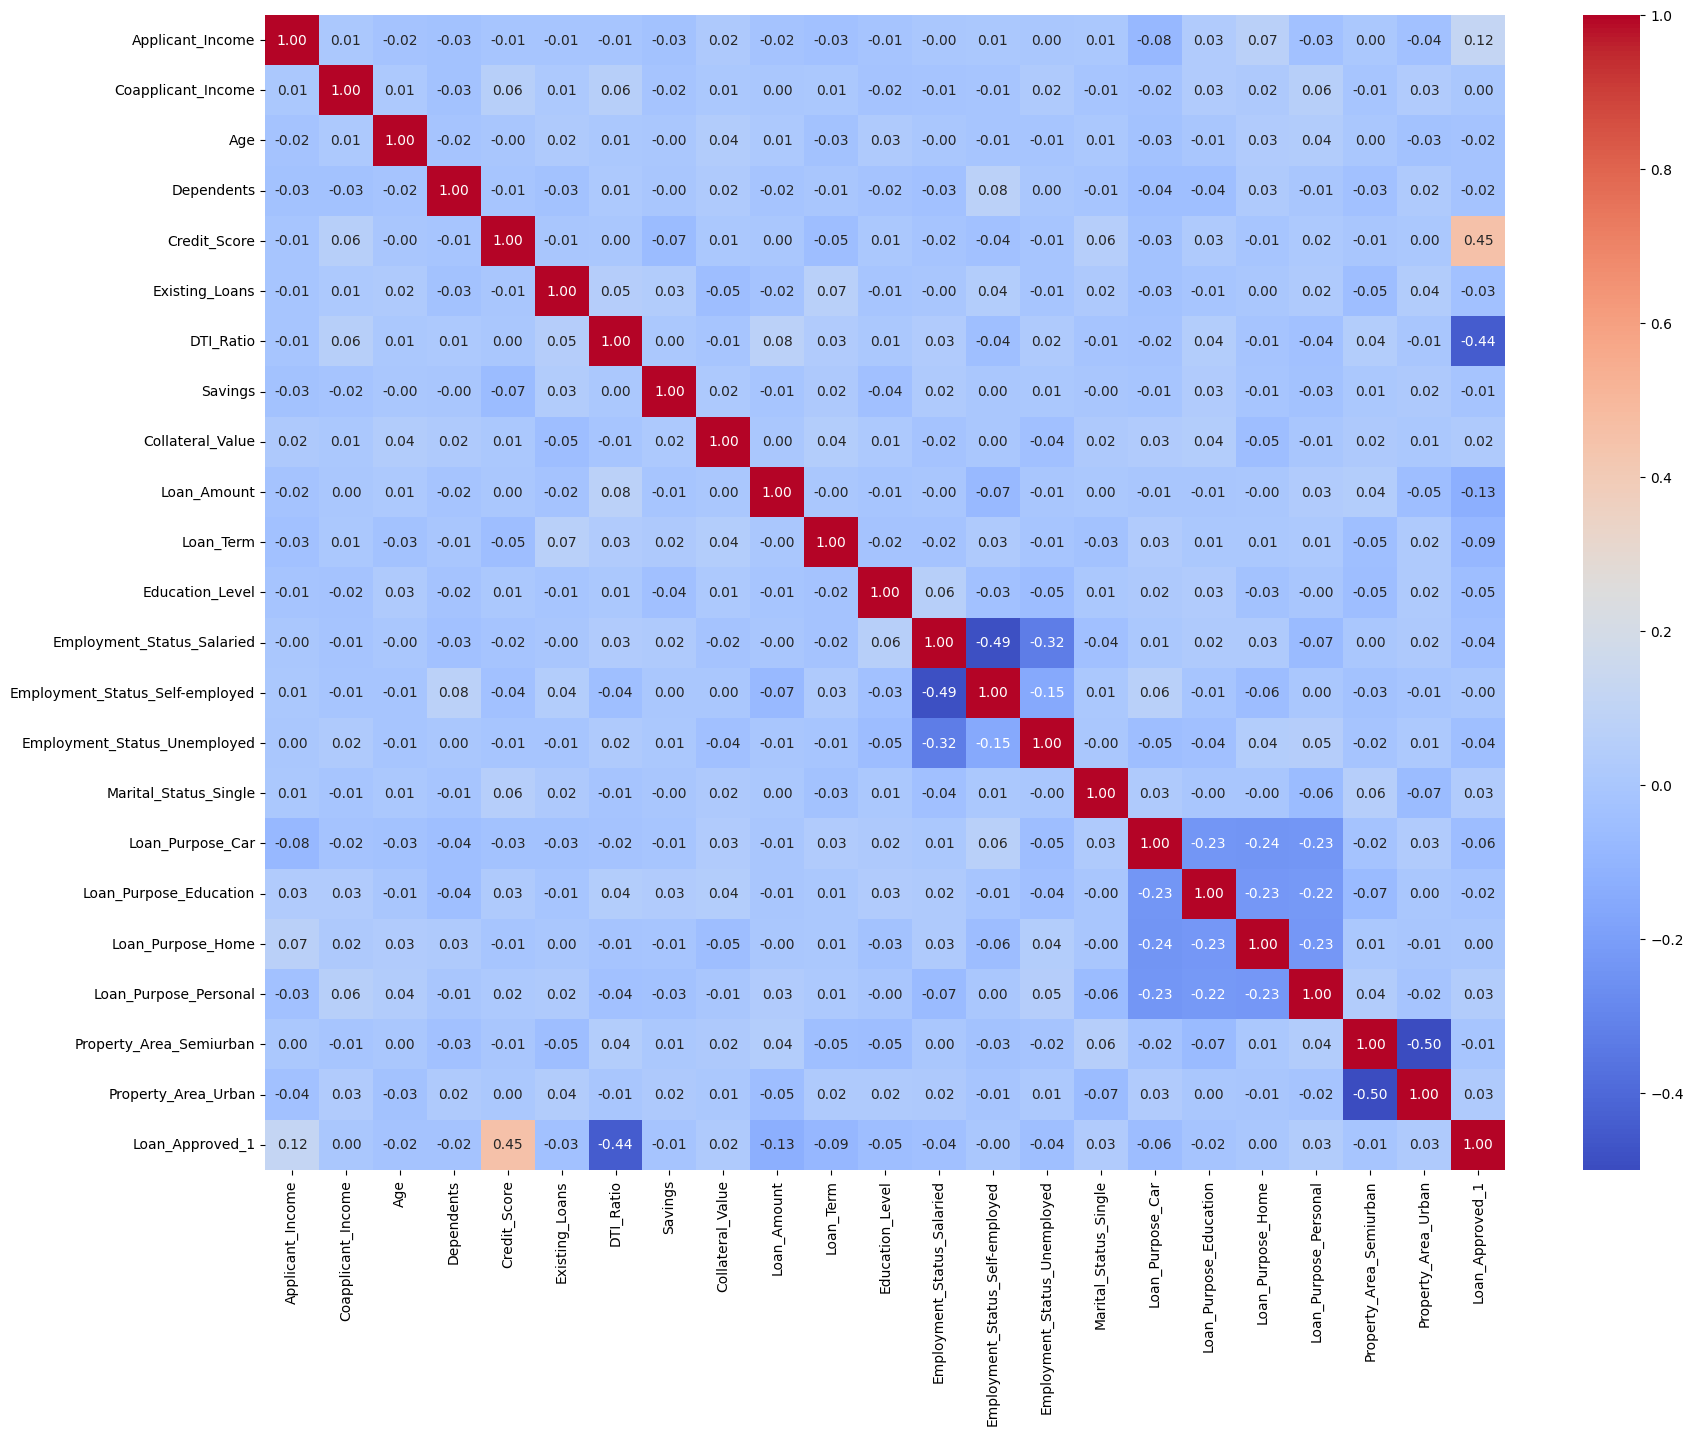

In [ ]:
plt.figure(figsize=(20,15))
sns.heatmap(
    corr_mat,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

In [ ]:
data["Gender"] = data["Gender"].map({"Female": 1, "Male": 0})

In [ ]:
data = pd.get_dummies(
    data,
    columns=["Employer_Category"],
    drop_first=True,
    dtype=int
)

**Train_Test_split**

In [ ]:
X=data.drop(["Loan_Approved_1"],axis=1)
Y=data["Loan_Approved_1"]
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
X_train.dtypes

,0
Applicant_Income,float64
Coapplicant_Income,float64
Age,float64
Dependents,float64
Credit_Score,float64
Existing_Loans,float64
DTI_Ratio,float64
Savings,float64
Collateral_Value,float64
Loan_Amount,float64


In [ ]:
from sklearn.preprocessing import StandardScaler

Scaler = StandardScaler()

X_train_scaled = Scaler.fit_transform(X_train)
X_test_scaled = Scaler.transform(X_test)

**Train and Evaluate Model**

In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()

log_reg.fit(X_train_scaled, Y_train)


LogisticRegression()

In [ ]:
y_pre=log_reg.predict(X_test_scaled)

**KNN model**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
Knn=KNeighborsClassifier(n_neighbors=3)
Knn.fit(X_train_scaled, Y_train)
y_pre=Knn.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, accuracy_score, recall_score, f1_score
print("confusin_matrix",confusion_matrix(Y_test,y_pre))
print("precision_score",precision_score(Y_test,y_pre))
print("accuracy_score",accuracy_score(Y_test,y_pre))
print("recall_score",recall_score(Y_test,y_pre))
print("f1_score",f1_score(Y_test,y_pre))





confusin_matrix [[135   4]
 [ 42  19]]
precision_score 0.8260869565217391
accuracy_score 0.77
recall_score 0.3114754098360656
f1_score 0.4523809523809524


Naive **Bayes**

In [ ]:
from sklearn.naive_bayes import GaussianNB
Nb=GaussianNB()
Nb.fit(X_train_scaled, Y_train)
y_pre=Nb.predict(X_test_scaled)
print("confusin_matrix",confusion_matrix(Y_test,y_pre))
print("precision_score",precision_score(Y_test,y_pre))
print("accuracy_score",accuracy_score(Y_test,y_pre))
print("recall_score",recall_score(Y_test,y_pre))
print("f1_score",f1_score(Y_test,y_pre))

confusin_matrix [[128  11]
 [ 16  45]]
precision_score 0.8035714285714286
accuracy_score 0.865
recall_score 0.7377049180327869
f1_score 0.7692307692307693
